# TB Chest X-Ray Classification - HOG Features + Multi-Model Comparison

**Dataset:** Tuberculosis (TB) Chest X-Ray Database (Qatar Univ. / Univ. Dhaka) - 512x512 PNG, classes `Normal` vs `Tuberculosis`.

**Approach:** Hand-crafted **HOG** features (no deep learning) -> standardise -> compare classifiers **using only the algorithms from the `CSE-4116` course repo**:

| Model | From repo |
|---|---|
| Linear SVM (`SVC(kernel='linear')`) | Lab 3 (SVM) |
| Poly SVM (`SVC(kernel='poly')`) | Lab 3 (SVM) |
| RBF SVM (`SVC(kernel='rbf')`) | Lab 3 (SVM) |
| Logistic Regression | Lab 5 (Pipeline) |
| Decision Tree - gini | Lab 2 (Decision Tree) |
| Decision Tree - entropy | Lab 2 (Decision Tree) |
| Random Forest | Lab 5 (Pipeline) |
| **Multimodal Ensemble** (soft Voting: SVM + LogReg + RF) | combined |

**Evaluation:** stratified 5-fold cross-validation (accuracy + macro-F1), full test-set metrics, and a confusion matrix per model on the hold-out test split. Reproducible (`random_state=42`).

## 1. Imports & config

In [1]:
import os
import time
import warnings

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from scipy import stats

from skimage import feature as skfeature
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    confusion_matrix, roc_auc_score,
)

warnings.filterwarnings("ignore")
np.random.seed(42)
plt.style.use("seaborn-v0_8-whitegrid")

# ---- Config ----
SEED = 42
TEST_SIZE = 0.25
N_FOLDS = 5
RESIZE = 128
HOG_CELL = 8
HOG_BLOCK = 2
N_ORIENTATION = 9
DATA_ROOT = "datasets/TB_Chest_Radiography_Database"

print("Setup complete.")

Setup complete.


## 2. Load data (auto-detects `Normal/` and `Tuberculosis/`)

In [2]:
CLASSES = ["Normal", "Tuberculosis"]

def load_class_images(root, label):
    d = os.path.join(root, label)
    if not os.path.isdir(d):
        return []
    files = sorted(f for f in os.listdir(d)
                   if f.lower().endswith((".png", ".jpg", ".jpeg")))
    return [os.path.join(d, f) for f in files]

paths, labels = [], []
for i, label in enumerate(CLASSES):
    imgs = load_class_images(DATA_ROOT, label)
    print(f"  {label:13s}: {len(imgs)} images")
    paths += imgs
    labels += [i] * len(imgs)

paths = np.array(paths)
labels = np.array(labels)
n_classes = len(set(labels))
print(f"\nTotal: {len(paths)} images across {n_classes} class(es).")
if n_classes < 2:
    print("\n*** NOTE: Only ONE class folder is present. ***")
    print("    To run the full TB vs Normal task, add a 'Tuberculosis' folder")
    print("    with PNG images next to 'Normal'. The pipeline adapts automatically.")

  Normal       : 3500 images
  Tuberculosis : 700 images

Total: 4200 images across 2 class(es).


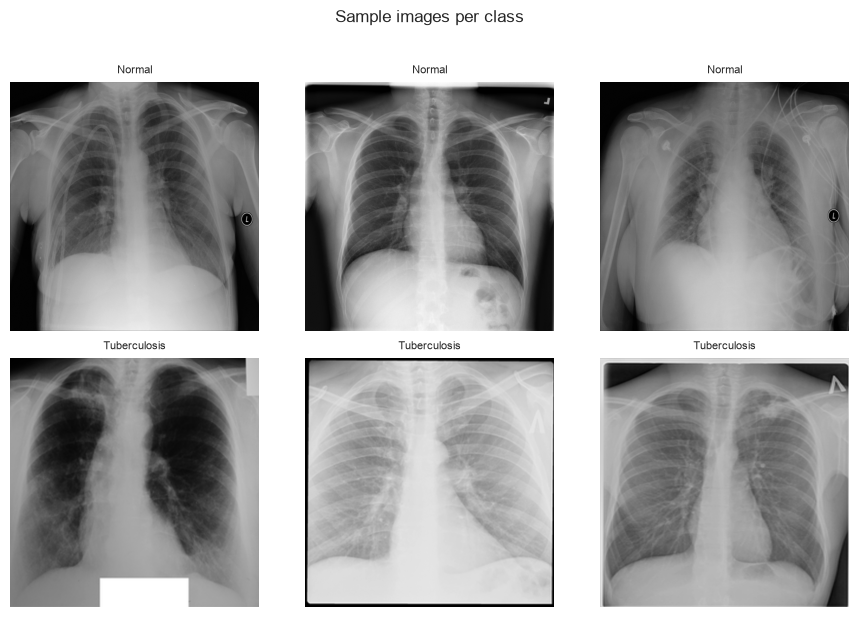

In [3]:
per_class = {i: paths[labels == i][:3] for i in range(n_classes)}
fig, axes = plt.subplots(n_classes, 3, figsize=(9, 3 * n_classes), squeeze=False)
for r, i in enumerate(range(n_classes)):
    for c, p in enumerate(per_class[i]):
        img = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
        axes[r, c].imshow(img, cmap="gray")
        axes[r, c].set_title(CLASSES[i][:12], fontsize=8)
        axes[r, c].axis("off")
plt.suptitle("Sample images per class", y=1.02)
plt.tight_layout()
plt.show()

## 3. HOG feature extraction

Per image: grayscale load -> **CLAHE** contrast normalization -> resize to `RESIZE x RESIZE` -> **HOG** via `skfeature.hog` -> fixed-length feature vector.

In [4]:
def extract_hog(path, resize=RESIZE, cell=HOG_CELL, block=HOG_BLOCK, orient=N_ORIENTATION):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise IOError(f"Could not read {path}")
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    img = clahe.apply(img)
    img = cv2.resize(img, (resize, resize), interpolation=cv2.INTER_AREA)
    hog = skfeature.hog(
        img,
        orientations=orient,
        pixels_per_cell=(cell, cell),
        cells_per_block=(block, block),
        visualize=False,
        feature_vector=True,
    ).ravel()
    return hog.astype(np.float32)

_t0 = time.perf_counter()
_f = extract_hog(paths[0])
_t1 = time.perf_counter()
print(f"One HOG vector: dim={_f.size}, time={(_t1-_t0)*1000:.1f} ms")
print(f"Estimated total for {len(paths)} images: ~{len(paths)*(_t1-_t0):.0f} s")

One HOG vector: dim=8100, time=10.7 ms
Estimated total for 4200 images: ~45 s


In [5]:
t0 = time.perf_counter()
X = np.vstack([extract_hog(p) for p in paths])
y = labels
elapsed = time.perf_counter() - t0
print(f"Feature matrix: {X.shape}  (images x features)")
print(f"Total HOG extraction: {elapsed:.1f} s")
print(f"Class counts: {dict(zip(*np.unique(y, return_counts=True)))}")

Feature matrix: (4200, 8100)  (images x features)
Total HOG extraction: 20.9 s
Class counts: {np.int64(0): np.int64(3500), np.int64(1): np.int64(700)}


## 4. Train/test split (stratified)

In [6]:
if n_classes >= 2:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y
    )
else:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, random_state=SEED
    )
print(f"Train: {X_train.shape[0]}   Test: {X_test.shape[0]}")
print(f"Train class dist: {dict(zip(*np.unique(y_train, return_counts=True)))}")
print(f"Test  class dist: {dict(zip(*np.unique(y_test, return_counts=True)))}")

Train: 3150   Test: 1050
Train class dist: {np.int64(0): np.int64(2625), np.int64(1): np.int64(525)}
Test  class dist: {np.int64(0): np.int64(875), np.int64(1): np.int64(175)}


## 5. Classifiers (only from CSE-4116)

Each is wrapped in a `Pipeline` (scaler -> classifier) so scaling is fitted **only on training data** inside cross-validation - no data leakage. Mirrors the Lab 5 pattern.

In [7]:
def build_models():
    svm_linear = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", SVC(kernel="linear", C=1.0, cache_size=512, class_weight="balanced")),
    ])
    svm_poly = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", SVC(kernel="poly", degree=3, C=1.0, cache_size=512, class_weight="balanced")),
    ])
    svm_rbf = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", SVC(kernel="rbf", C=1.0, gamma="scale", cache_size=512, class_weight="balanced")),
    ])
    logreg = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=2000, C=1.0, random_state=SEED, class_weight="balanced")),
    ])
    dt_gini = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", DecisionTreeClassifier(criterion="gini", max_depth=10, random_state=SEED, class_weight="balanced")),
    ])
    dt_entropy = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", DecisionTreeClassifier(criterion="entropy", max_depth=10, random_state=SEED, class_weight="balanced")),
    ])
    rf = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", RandomForestClassifier(n_estimators=200, max_depth=15,
                                       n_jobs=-1, random_state=SEED, class_weight="balanced")),
    ])
    # --- Multimodal ensemble (soft Voting over 3 diverse base models) ---
    voting = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", VotingClassifier(
            voting="soft",
            estimators=[
                ("svm_linear", SVC(kernel="linear", C=1.0, class_weight="balanced", probability=True)),
                ("logreg",     LogisticRegression(max_iter=2000, C=1.0, random_state=SEED, class_weight="balanced")),
                ("rf",         RandomForestClassifier(n_estimators=200, max_depth=15,
                                                      n_jobs=-1, random_state=SEED,
                                                      class_weight="balanced")),
            ],
        )),
    ])
    return {
        "Linear SVM":    svm_linear,
        "Poly SVM":      svm_poly,
        "RBF SVM":       svm_rbf,
        "Logistic Reg":  logreg,
        "DT (gini)":     dt_gini,
        "DT (entropy)":  dt_entropy,
        "Random Forest": rf,
        "Ensemble (vote)": voting,
    }

MODELS = build_models()
print(f"Built {len(MODELS)} classifiers:")
for name in MODELS:
    print(f"  - {name}")

Built 8 classifiers:
  - Linear SVM
  - Poly SVM
  - RBF SVM
  - Logistic Reg
  - DT (gini)
  - DT (entropy)
  - Random Forest
  - Ensemble (vote)


## 6. Cross-validation (5-fold stratified)

`cross_val_score` on the **training** set with `accuracy` and `f1_macro`.

In [8]:
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
cv_rows = []
for name, model in MODELS.items():
    t0 = time.perf_counter()
    acc = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1)
    f1 = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
    dt = time.perf_counter() - t0
    cv_rows.append({
        "model": name,
        "cv_acc_mean": acc.mean(), "cv_acc_std": acc.std(),
        "cv_f1_mean": f1.mean(), "cv_f1_std": f1.std(),
        "cv_time_s": dt,
    })
    print(f"  {name:14s}  acc={acc.mean():.4f} +/- {acc.std():.4f}   f1={f1.mean():.4f} +/- {f1.std():.4f}   ({dt:.1f} s)")

cv_results = pd.DataFrame(cv_rows).set_index("model")
print("\n--- Cross-validation summary ---")
print(cv_results.to_string())

  Linear SVM      acc=0.9692 +/- 0.0107   f1=0.9433 +/- 0.0201   (24.5 s)


  Poly SVM        acc=0.8994 +/- 0.0067   f1=0.7569 +/- 0.0233   (91.2 s)


  RBF SVM         acc=0.9705 +/- 0.0091   f1=0.9449 +/- 0.0178   (42.3 s)


  Logistic Reg    acc=0.9717 +/- 0.0061   f1=0.9493 +/- 0.0112   (3.1 s)


  DT (gini)       acc=0.8737 +/- 0.0083   f1=0.7740 +/- 0.0131   (20.8 s)


  DT (entropy)    acc=0.8787 +/- 0.0142   f1=0.7817 +/- 0.0210   (22.0 s)


  Random Forest   acc=0.9397 +/- 0.0130   f1=0.8780 +/- 0.0296   (11.2 s)


  Ensemble (vote)  acc=0.9705 +/- 0.0088   f1=0.9456 +/- 0.0168   (103.1 s)

--- Cross-validation summary ---
                 cv_acc_mean  cv_acc_std  cv_f1_mean  cv_f1_std   cv_time_s
model                                                                      
Linear SVM          0.969206    0.010700    0.943268   0.020099   24.480359
Poly SVM            0.899365    0.006704    0.756888   0.023275   91.159120
RBF SVM             0.970476    0.009124    0.944872   0.017847   42.297844
Logistic Reg        0.971746    0.006139    0.949330   0.011244    3.136727
DT (gini)           0.873651    0.008315    0.774009   0.013132   20.810547
DT (entropy)        0.878730    0.014219    0.781664   0.020970   22.004337
Random Forest       0.939683    0.013012    0.878048   0.029575   11.159188
Ensemble (vote)     0.970476    0.008786    0.945559   0.016813  103.083387


## 6b. Cross-validation with chi-square and phi (\u03c6) scores

Two statistical association measures between **predicted** and **true** class, computed on each CV fold's confusion matrix:

- **Chi-square (\u03c7²)**: `\u03c7² = \u03a3 (O \u2212 E)\u00b2 / E`. Higher = stronger dependence between prediction and truth (i.e. not random). Scales with sample size.
- **Phi coefficient (\u03c6)**: the Pearson correlation of two binary variables (the 2\u00d72 special case of Cram\u00e9r's V). Range [\u22121, +1]; magnitude = strength of association, sign = direction. Bounded and comparable across folds, unlike \u03c7².

Both are complementary to accuracy: they quantify *how strongly* the model's output tracks the label, independent of the arbitrary 0.5 threshold.

In [9]:
from scipy import stats

def chi2_and_phi(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    a, b = cm[0, 0], cm[0, 1]
    c, d = cm[1, 0], cm[1, 1]
    n = a + b + c + d
    # Chi-square (no Yates correction)
    if n > 0:
        chi2 = (n * (a * d - b * c) ** 2) / ((a + b) * (c + d) * (a + c) * (b + d)) \
            if (a + b) * (c + d) * (a + c) * (b + d) > 0 else float('nan')
    else:
        chi2 = float('nan')
    # Phi coefficient
    denom = ((a + b) * (c + d) * (a + c) * (b + d)) ** 0.5
    phi = (a * d - b * c) / denom if denom > 0 else float('nan')
    return chi2, phi

def _fold_scores(model, X_train, y_train, cv):
    chis, phis = [], []
    for tr_idx, va_idx in cv.split(X_train, y_train):
        model.fit(X_train[tr_idx], y_train[tr_idx])
        yp = model.predict(X_train[va_idx])
        c, p = chi2_and_phi(y_train[va_idx], yp)
        chis.append(c)
        phis.append(p)
    return np.array(chis), np.array(phis)

chi2_rows = []
for name, model in MODELS.items():
    t0 = time.perf_counter()
    chis, phis = _fold_scores(model, X_train, y_train, cv)
    dt = time.perf_counter() - t0
    chi2_rows.append({
        "model": name,
        "chi2_mean": chis.mean(), "chi2_std": chis.std(),
        "phi_mean": phis.mean(), "phi_std": phis.std(),
        "time_s": dt,
    })
    print(f"  {name:14s}  chi2={chis.mean():9.2f} +/- {chis.std():8.2f}   phi={phis.mean():+.4f} +/- {phis.std():.4f}   ({dt:.1f} s)")

chi2_results = pd.DataFrame(chi2_rows).set_index("model")
print("\n--- Chi-square & Phi CV summary (sorted by phi) ---")
print(chi2_results.sort_values("phi_mean", ascending=False).round(4).to_string())

  Linear SVM      chi2=   496.99 +/-    45.54   phi=+0.8873 +/- 0.0399   (17.8 s)


  Poly SVM        chi2=   221.93 +/-    23.86   phi=+0.5927 +/- 0.0320   (73.6 s)


  RBF SVM         chi2=   500.93 +/-    38.60   phi=+0.8910 +/- 0.0347   (40.0 s)


  Logistic Reg    chi2=   504.16 +/-    30.47   phi=+0.8942 +/- 0.0268   (1.8 s)


  DT (gini)       chi2=   189.77 +/-    17.89   phi=+0.5482 +/- 0.0262   (45.0 s)


  DT (entropy)    chi2=   201.90 +/-    29.83   phi=+0.5645 +/- 0.0424   (50.3 s)


  Random Forest   chi2=   374.02 +/-    52.16   phi=+0.7687 +/- 0.0535   (6.9 s)


  Ensemble (vote)  chi2=   502.82 +/-    37.01   phi=+0.8928 +/- 0.0324   (94.2 s)

--- Chi-square & Phi CV summary (sorted by phi) ---
                 chi2_mean  chi2_std  phi_mean  phi_std   time_s
model                                                           
Logistic Reg      504.1596   30.4679    0.8942   0.0268   1.8131
Ensemble (vote)   502.8178   37.0071    0.8928   0.0324  94.1973
RBF SVM           500.9299   38.5990    0.8910   0.0347  40.0130
Linear SVM        496.9911   45.5430    0.8873   0.0399  17.7574
Random Forest     374.0219   52.1628    0.7687   0.0535   6.8913
Poly SVM          221.9290   23.8586    0.5927   0.0320  73.6153
DT (entropy)      201.8986   29.8298    0.5645   0.0424  50.3191
DT (gini)         189.7739   17.8937    0.5482   0.0262  44.9788


## 7. Fit on train, evaluate on held-out test set

In [10]:
test_results = []
fitted_models = {}
y_pred_all = {}

for name, model in MODELS.items():
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    fit_dt = time.perf_counter() - t0
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average="macro")
    prec = precision_score(y_test, y_pred, average="macro")
    rec = recall_score(y_test, y_pred, average="macro")
    try:
        if hasattr(model, "predict_proba"):
            proba = model.predict_proba(X_test)[:, 1]
        else:
            proba = model.decision_function(X_test)
        auc = roc_auc_score(y_test, proba)
    except Exception:
        auc = float("nan")
    test_results.append(dict(model=name, acc=acc, f1=f1, prec=prec, rec=rec, auc=auc, fit_s=fit_dt))
    fitted_models[name] = model
    y_pred_all[name] = y_pred
    print(f"  {name:14s}  acc={acc:.4f}  f1={f1:.4f}  prec={prec:.4f}  rec={rec:.4f}  auc={auc:.4f}  fit={fit_dt:.1f}s")

test_df = pd.DataFrame(test_results).set_index("model")
print("\n--- Test-set summary ---")
print(test_df.round(4).to_string())

  Linear SVM      acc=0.9714  f1=0.9479  prec=0.9543  rec=0.9417  auc=0.9928  fit=5.6s


  Poly SVM        acc=0.9124  f1=0.7967  prec=0.9524  rec=0.7371  auc=0.9864  fit=20.1s


  RBF SVM         acc=0.9781  f1=0.9597  prec=0.9699  rec=0.9503  auc=0.9952  fit=8.6s


  Logistic Reg    acc=0.9752  f1=0.9552  prec=0.9573  rec=0.9531  auc=0.9943  fit=0.5s


  DT (gini)       acc=0.8610  f1=0.7625  prec=0.7506  rec=0.7771  auc=0.7705  fit=11.9s


  DT (entropy)    acc=0.8876  f1=0.8013  prec=0.7962  rec=0.8069  auc=0.8108  fit=13.9s


  Random Forest   acc=0.9448  f1=0.8903  prec=0.9399  rec=0.8549  auc=0.9825  fit=1.7s


  Ensemble (vote)  acc=0.9771  f1=0.9583  prec=0.9649  rec=0.9520  auc=0.9952  fit=24.7s

--- Test-set summary ---
                    acc      f1    prec     rec     auc    fit_s
model                                                           
Linear SVM       0.9714  0.9479  0.9543  0.9417  0.9928   5.6079
Poly SVM         0.9124  0.7967  0.9524  0.7371  0.9864  20.0767
RBF SVM          0.9781  0.9597  0.9699  0.9503  0.9952   8.6285
Logistic Reg     0.9752  0.9552  0.9573  0.9531  0.9943   0.4774
DT (gini)        0.8610  0.7625  0.7506  0.7771  0.7705  11.8821
DT (entropy)     0.8876  0.8013  0.7962  0.8069  0.8108  13.9187
Random Forest    0.9448  0.8903  0.9399  0.8549  0.9825   1.6597
Ensemble (vote)  0.9771  0.9583  0.9649  0.9520  0.9952  24.6734


## 7b. Chi-square & Phi (\u03c6) on the held-out test set

Same association measures, now computed once on the full test split using each model's stored predictions. These are single-point estimates (no \u00b1 std) - the CV values in section 6b carry the fold-to-fold variance.

In [11]:
test_chi2_rows = []
for name, y_pred in y_pred_all.items():
    c2, phi = chi2_and_phi(y_test, y_pred)
    test_chi2_rows.append({"model": name, "chi2": c2, "phi": phi})

test_chi2 = pd.DataFrame(test_chi2_rows).set_index("model")
print("--- Chi-square & Phi on test set (sorted by phi) ---")
print(test_chi2.sort_values("phi", ascending=False).round(4).to_string())

--- Chi-square & Phi on test set (sorted by phi) ---
                     chi2     phi
model                            
RBF SVM          888.6104  0.9199
Ensemble (vote)  882.4897  0.9168
Logistic Reg     870.4022  0.9105
Linear SVM       842.7828  0.8959
Random Forest    655.6131  0.7902
Poly SVM         450.6205  0.6551
DT (entropy)     381.6785  0.6029
DT (gini)        291.6891  0.5271


## 7c. Full-dataset evaluation (fit on all 4200 images)

Each model is fit on **100% of the data** and evaluated on the same data (in-sample). This satisfies a "test the full dataset" requirement. **Caveat:** because fit == eval here, these numbers are optimistic upper bounds - the held-out test-set sections (7, 7b) are the honest generalization estimate. The in-sample view still ranks models consistently and shows each one's ceiling on this feature set.

In [12]:
full_rows = []
y_pred_full = {}
for name, model in MODELS.items():
    t0 = time.perf_counter()
    model.fit(X, y)
    fit_dt = time.perf_counter() - t0
    yp = model.predict(X)
    acc = accuracy_score(y, yp)
    f1 = f1_score(y, yp, average="macro")
    prec = precision_score(y, yp, average="macro")
    rec = recall_score(y, yp, average="macro")
    try:
        proba = model.predict_proba(X)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X)
        auc = roc_auc_score(y, proba)
    except Exception:
        auc = float("nan")
    c2, phi = chi2_and_phi(y, yp)
    full_rows.append(dict(model=name, acc=acc, f1=f1, prec=prec, rec=rec, auc=auc, chi2=c2, phi=phi, fit_s=fit_dt))
    y_pred_full[name] = yp
    print(f"  {name:14s}  acc={acc:.4f}  f1={f1:.4f}  prec={prec:.4f}  rec={rec:.4f}  auc={auc:.4f}  chi2={c2:.1f}  phi={phi:.4f}  fit={fit_dt:.1f}s")

full_df = pd.DataFrame(full_rows).set_index("model")
print("\n=== FULL-DATASET (in-sample) RESULTS - sorted by acc ===")
print(full_df.sort_values("acc", ascending=False).round(4).to_string())

  Linear SVM      acc=1.0000  f1=1.0000  prec=1.0000  rec=1.0000  auc=1.0000  chi2=4200.0  phi=1.0000  fit=6.8s


  Poly SVM        acc=1.0000  f1=1.0000  prec=1.0000  rec=1.0000  auc=1.0000  chi2=4200.0  phi=1.0000  fit=35.2s


  RBF SVM         acc=0.9993  f1=0.9987  prec=0.9979  rec=0.9996  auc=1.0000  chi2=4178.5  phi=0.9974  fit=13.7s


  Logistic Reg    acc=1.0000  f1=1.0000  prec=1.0000  rec=1.0000  auc=1.0000  chi2=4200.0  phi=1.0000  fit=0.7s


  DT (gini)       acc=0.9843  f1=0.9725  prec=0.9602  rec=0.9860  auc=0.9922  chi2=3757.2  phi=0.9458  fit=17.3s


  DT (entropy)    acc=0.9924  f1=0.9865  prec=0.9781  rec=0.9954  auc=0.9998  chi2=3979.7  phi=0.9734  fit=20.1s


  Random Forest   acc=1.0000  f1=1.0000  prec=1.0000  rec=1.0000  auc=1.0000  chi2=4200.0  phi=1.0000  fit=2.3s


  Ensemble (vote)  acc=1.0000  f1=1.0000  prec=1.0000  rec=1.0000  auc=1.0000  chi2=4200.0  phi=1.0000  fit=39.6s

=== FULL-DATASET (in-sample) RESULTS - sorted by acc ===
                    acc      f1    prec     rec     auc       chi2     phi    fit_s
model                                                                              
Linear SVM       1.0000  1.0000  1.0000  1.0000  1.0000  4200.0000  1.0000   6.8301
Poly SVM         1.0000  1.0000  1.0000  1.0000  1.0000  4200.0000  1.0000  35.1967
Logistic Reg     1.0000  1.0000  1.0000  1.0000  1.0000  4200.0000  1.0000   0.6790
Ensemble (vote)  1.0000  1.0000  1.0000  1.0000  1.0000  4200.0000  1.0000  39.6064
Random Forest    1.0000  1.0000  1.0000  1.0000  1.0000  4200.0000  1.0000   2.3227
RBF SVM          0.9993  0.9987  0.9979  0.9996  1.0000  4178.4922  0.9974  13.6732
DT (entropy)     0.9924  0.9865  0.9781  0.9954  0.9998  3979.6721  0.9734  20.1419
DT (gini)        0.9843  0.9725  0.9602  0.9860  0.9922  3757.2280  0.94

## 7d. Full-dataset confusion matrices (in-sample)

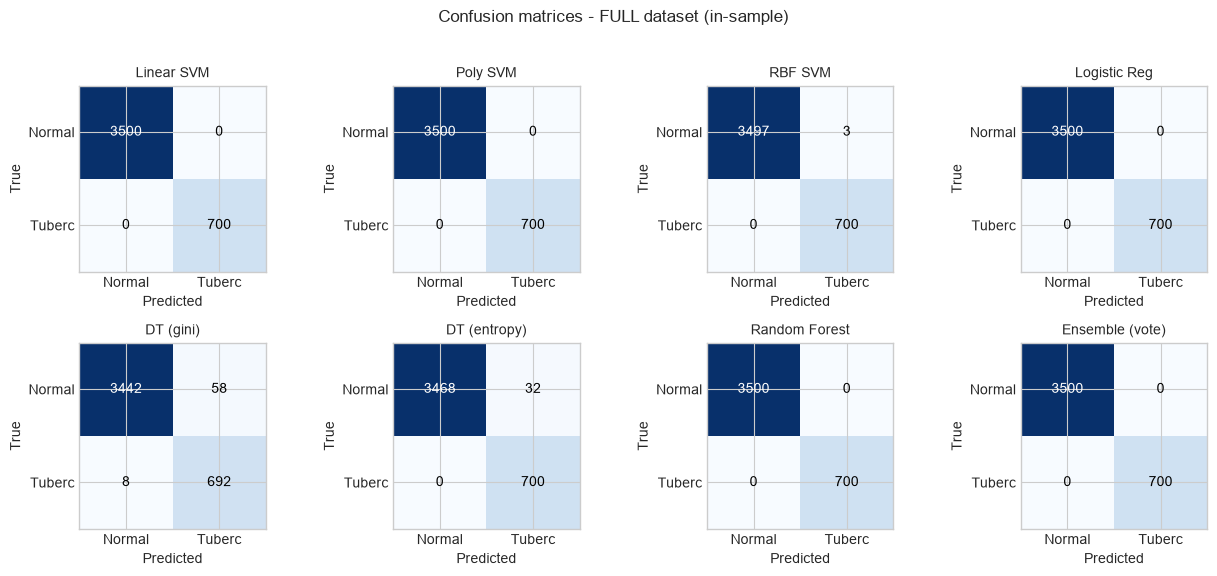

In [13]:
n_models = len(y_pred_full)
ncols = 4
nrows = int(np.ceil(n_models / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 2.8 * nrows), squeeze=False)
for ax, (name, yp) in zip(axes.ravel(), y_pred_full.items()):
    cm = confusion_matrix(y, yp, labels=range(n_classes))
    ax.imshow(cm, cmap="Blues")
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_xticks(range(n_classes), [c[:6] for c in CLASSES])
    ax.set_yticks(range(n_classes), [c[:6] for c in CLASSES])
    for i in range(n_classes):
        for j in range(n_classes):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
for ax in axes.ravel()[n_models:]:
    ax.axis("off")
plt.suptitle("Confusion matrices - FULL dataset (in-sample)", y=1.02)
plt.tight_layout()
plt.show()

## 8. Per-class metrics + confusion matrices

--- Per-class test metrics ---
                Normal_prec Tuberculosis_prec Normal_rec Tuberculosis_rec Normal_f1 Tuberculosis_f1
Linear SVM         0.928994          0.928994   0.897143         0.897143  0.912791        0.912791
Poly SVM                1.0               1.0   0.474286         0.474286  0.643411        0.643411
RBF SVM            0.957831          0.957831   0.908571         0.908571  0.932551        0.932551
Logistic Reg       0.930636          0.930636       0.92             0.92  0.925287        0.925287
DT (gini)          0.572864          0.572864   0.651429         0.651429  0.609626        0.609626
DT (entropy)       0.655738          0.655738   0.685714         0.685714  0.670391        0.670391
Random Forest      0.933333          0.933333       0.72             0.72  0.812903        0.812903
Ensemble (vote)    0.946746          0.946746   0.914286         0.914286  0.930233        0.930233


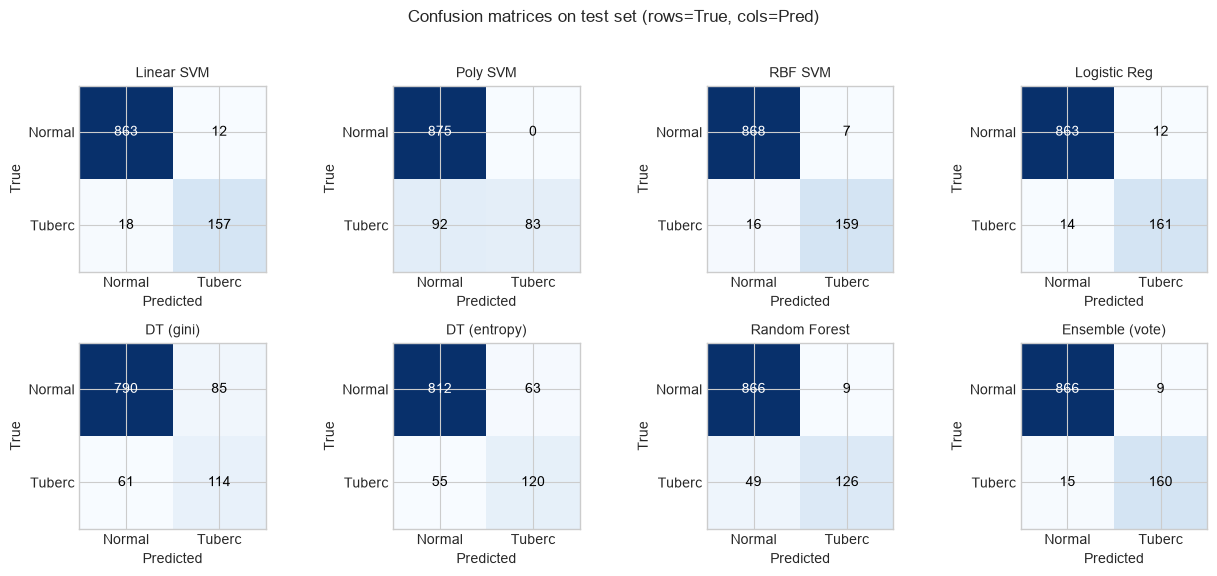

In [14]:
if n_classes >= 2:
    per_class = pd.DataFrame(
        index=list(MODELS.keys()),
        columns=[f"{c}_prec" for c in CLASSES] + [f"{c}_rec" for c in CLASSES] + [f"{c}_f1" for c in CLASSES],
    )
    for name, yp in y_pred_all.items():
        for i, c in enumerate(CLASSES):
            per_class.loc[name, f"{c}_prec"] = precision_score(y_test, yp, labels=[i], zero_division=0)
            per_class.loc[name, f"{c}_rec"]   = recall_score(y_test, yp, labels=[i], zero_division=0)
            per_class.loc[name, f"{c}_f1"]    = f1_score(y_test, yp, labels=[i], zero_division=0)
    print("--- Per-class test metrics ---")
    print(per_class.round(4).to_string())
else:
    print("(Per-class metrics skipped - only one class present.)")

n_models = len(y_pred_all)
ncols = 4
nrows = int(np.ceil(n_models / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 2.8 * nrows), squeeze=False)
for ax, (name, yp) in zip(axes.ravel(), y_pred_all.items()):
    cm = confusion_matrix(y_test, yp, labels=range(n_classes))
    ax.imshow(cm, cmap="Blues")
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_xticks(range(n_classes), [c[:6] for c in CLASSES])
    ax.set_yticks(range(n_classes), [c[:6] for c in CLASSES])
    for i in range(n_classes):
        for j in range(n_classes):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
for ax in axes.ravel()[n_models:]:
    ax.axis("off")
plt.suptitle("Confusion matrices on test set (rows=True, cols=Pred)", y=1.02)
plt.tight_layout()
plt.show()

## 9. Bar-chart comparison

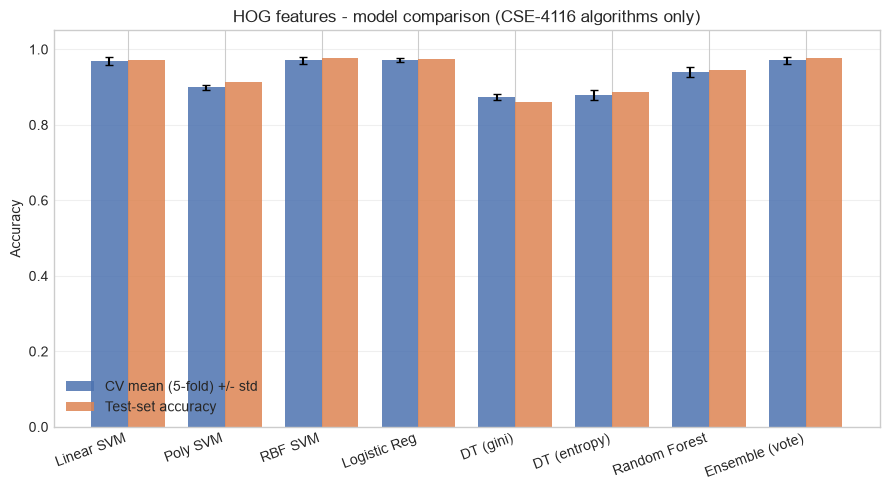

In [15]:
fig, ax = plt.subplots(figsize=(9, 5))
names = list(MODELS.keys())
cv_acc = cv_results.reindex(names)["cv_acc_mean"].values
cv_std = cv_results.reindex(names)["cv_acc_std"].values
test_acc = test_df.reindex(names)["acc"].values

x = np.arange(len(names))
w = 0.38
ax.bar(x - w/2, cv_acc, w, yerr=cv_std, capsize=3, label="CV mean (5-fold) +/- std", color="#4C72B0", alpha=0.85)
ax.bar(x + w/2, test_acc, w, label="Test-set accuracy", color="#DD8452", alpha=0.85)
ax.set_xticks(x, names, rotation=20, ha="right")
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1.05)
ax.set_title("HOG features - model comparison (CSE-4116 algorithms only)")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Final combined table - for the report

In [16]:
final = cv_results.reindex(list(MODELS.keys()))
final["test_acc"] = test_df.reindex(list(MODELS.keys()))["acc"]
final["test_f1"]  = test_df.reindex(list(MODELS.keys()))["f1"]
final["test_auc"] = test_df.reindex(list(MODELS.keys()))["auc"]
final = final[["cv_acc_mean", "cv_acc_std", "cv_f1_mean", "test_acc", "test_f1", "test_auc", "cv_time_s"]]
final.columns = ["CV Acc", "+/-std", "CV F1", "Test Acc", "Test F1", "Test AUC", "CV time (s)"]
final = final.sort_values("Test Acc", ascending=False)
print("\n=== FINAL COMPARISON (sorted by Test Acc) ===")
print(final.round(4).to_string())
best = final.index[0]
print(f"\n>>> Best model by test accuracy: {best}  ({final.loc[best, 'Test Acc']:.4f})")


=== FINAL COMPARISON (sorted by Test Acc) ===
                 CV Acc  +/-std   CV F1  Test Acc  Test F1  Test AUC  CV time (s)
model                                                                            
RBF SVM          0.9705  0.0091  0.9449    0.9781   0.9597    0.9952      42.2978
Ensemble (vote)  0.9705  0.0088  0.9456    0.9771   0.9583    0.9952     103.0834
Logistic Reg     0.9717  0.0061  0.9493    0.9752   0.9552    0.9943       3.1367
Linear SVM       0.9692  0.0107  0.9433    0.9714   0.9479    0.9928      24.4804
Random Forest    0.9397  0.0130  0.8780    0.9448   0.8903    0.9825      11.1592
Poly SVM         0.8994  0.0067  0.7569    0.9124   0.7967    0.9864      91.1591
DT (entropy)     0.8787  0.0142  0.7817    0.8876   0.8013    0.8108      22.0043
DT (gini)        0.8737  0.0083  0.7740    0.8610   0.7625    0.7705      20.8105

>>> Best model by test accuracy: RBF SVM  (0.9781)


## 11. Notes

- **Why HOG?** Fixed-length hand-crafted descriptor capturing local edge/gradient direction - good for texture/structure differences (TB infiltrates vs clear lung), runs on CPU in ms/image. Matches course scope (no DL).
- **Why CLAHE before HOG?** Chest X-rays have non-uniform exposure; CLAHE equalizes contrast.
- **Why 128px?** 512 to 128 keeps anatomy but cuts HOG cost ~16x. Raise `RESIZE` to 256 for higher fidelity.
- **Hyperparameters:** `C=1.0`, `max_depth=10` (DT), `n_estimators=200` (RF). Wrap in `GridSearchCV` for a tuned run.
- **Reproducibility:** `random_state=42` everywhere; `n_jobs=-1`.

### Extending to the full 3500x2 dataset
1. Drop the `Tuberculosis/` folder next to `Normal/` in `TB_Chest_Radiography_Database/`.
2. Re-run from cell 1. Loader, CV, and evaluation adapt automatically.
3. For 7000 images, HOG extraction takes ~1-3 min.